# Foundations 8: Differential equations

*Learning path: foundations, part 8 of 9.* [Index](README.md) · Previous: [Calculus](07-calculus.ipynb) · Next: [Geometry and conic sections](09-geometry-and-conics.ipynb)

Most laws of nature do not say what a quantity *is*, but how fast it *changes*: a population grows in proportion to
its size, a hot cup of coffee cools in proportion to how much hotter it is than the room, a spring pulls back in
proportion to how far it is stretched. Such laws are **differential equations**: equations for an unknown function
that involve its derivatives. You will learn

* what a differential equation and its solution are, and how to check a solution,
* how to solve the common ones exactly with `dsolve`, with and without **initial conditions**,
* growth and decay, cooling, and the spring (free, damped and forced),
* how to solve any equation numerically with `odesolve` and draw it with `odeplot`, argument by argument,
* the pendulum, and how to read a **phase portrait**.

## 1. What is a differential equation?

The equation

$$y' = k\,y$$

says: the rate of change of $y$ is $k$ times $y$. It does not tell us $y$ directly. A **solution** is a function
$y(t)$ that makes the equation true for every $t$. Let's check that $y = C e^{kt}$ is one, for any constant $C$: put it
into both sides and compare.

In [1]:
y = C*exp(k*t);
deriv(y, t)
simplify(deriv(y, t) - k*y)
clear

exp(k*t)*C*k

> `deriv`: Derivative of expr with respect to the variable given (other letters count as constants: a partial derivative).

0

> `simplify`: simplify(expr) writes expr in one fixed form: a fraction N/D of multiplied-out polynomials (in the symbols, constants and functions of expr) with common factors cancelled, square roots moved out of denominators, and sin^2 + cos^2 = 1 used in whichever direction is shorter.

The difference is 0, so $y = Ce^{kt}$ solves the equation, whatever the constant $C$ is. A first-order equation has a
whole family of solutions with one free constant. To pick one, we need one more fact, the **initial condition**: the
value of $y$ at the start, $y(0) = y_0$. Then $C = y_0$.

## 2. Solving with `dsolve`

`dsolve(equation, y, t)` solves an equation for the unknown function $y$ of the variable $t$. Write the derivatives
with `d`: `d(y, t)` is $y'$, `d(y, t, 2)` is $y''$. The answer contains the free constants `C1`, `C2`, ...

In [2]:
dsolve(d(y, t) == k*y, y, t)

exp(k*t)*C1

> `dsolve`: Exact solution of a differential equation written with y, d(y, x), d(y, x, 2), ...: linear with constant coefficients of any order (forcing by polynomials, exponentials, sines and cosines), first-order linear y' + p(x) y = q(x), separable y' = f(x) g(y) (logistic, y' = x/y, ...), and Cauchy–Euler x^2 y'' + b x y' + c y = 0.

With initial conditions add two more arguments: the starting time $t_0$, and a list with the starting values
$[y(t_0), y'(t_0), \ldots]$ (one value for each order of the equation):

```
dsolve(equation, y, t, t0, [y(t0), d(y, t0), ...])
```

### Radioactive decay

Carbon-14 decays with a half-life of 5730 years: the decay rate is proportional to the amount left,
$N' = -k N$ with $k = \log 2/5730$ per year. Start with 100 grams at $t = 0$:

In [3]:
k = log(2)/5730;
N = dsolve(d(N, t) == -k*N, N, t, 0, [100])
eval(subs(N, t, 5730))
eval(subs(N, t, 20000))
solve(N == 25, t)

100*exp(-t*log(2)/5730)

> `dsolve`: Exact solution of a differential equation written with y, d(y, x), d(y, x, 2), ...: linear with constant coefficients of any order (forcing by polynomials, exponentials, sines and cosines), first-order linear y' + p(x) y = q(x), separable y' = f(x) g(y) (logistic, y' = x/y, ...), and Cauchy–Euler x^2 y'' + b x y' + c y = 0.

50.0

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

8.897837762759563

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

11460

> `solve`: Solves f = 0 (or an equation lhs == rhs) for x and returns all solutions in a row.

After one half-life, 50 g are left; after 20000 years, about 8.9 g; a quarter (25 g) is left after two half-lives,
11460 years. That is how radiocarbon dating works: the fraction of carbon-14 left in a bone tells its age.

The plot shows the amount against time. The horizontal axis is time in years, from 0 to 30000; the vertical axis is
grams of carbon-14 left:

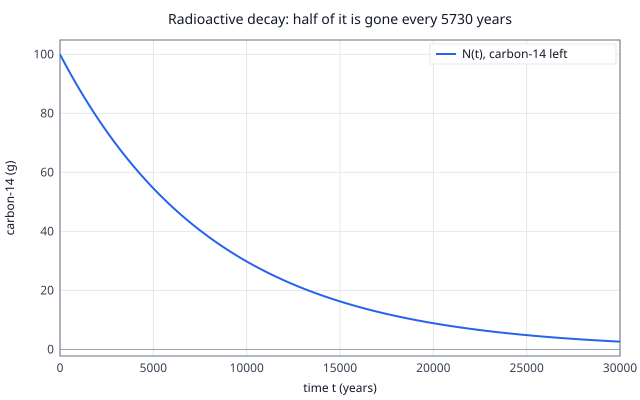

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [4]:
p = plot(N, t, 0, 30000);
labels(title(legend(p, "N(t), carbon-14 left"), "Radioactive decay: half of it is gone every 5730 years"), "time t (years)", "carbon-14 (g)")
clear

### Newton's law of cooling

A cup of coffee at 90 °C stands in a room at 20 °C. It cools at a rate proportional to the difference with the room:
$T' = -k(T - 20)$. Galileo keeps $k$ as a symbol:

In [5]:
T = dsolve(d(T, t) == -k*(T - 20), T, t, 0, [90])

70*exp(-k*t)+20

> `dsolve`: Exact solution of a differential equation written with y, d(y, x), d(y, x, 2), ...: linear with constant coefficients of any order (forcing by polynomials, exponentials, sines and cosines), first-order linear y' + p(x) y = q(x), separable y' = f(x) g(y) (logistic, y' = x/y, ...), and Cauchy–Euler x^2 y'' + b x y' + c y = 0.

The difference with the room, $70e^{-kt}$, decays exponentially. Measured: after 10 minutes the coffee is at 60 °C.
That determines $k$:

In [6]:
solve(subs(T, t, 10) == 60, k)

-log(4/7)/10

> `solve`: Solves f = 0 (or an equation lhs == rhs) for x and returns all solutions in a row.

By hand: $70e^{-10k} + 20 = 60$ gives $e^{-10k} = 4/7$, so $k = -\log(4/7)/10 = \log(7/4)/10$, about 0.056 per
minute.

0.05596157879354227

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

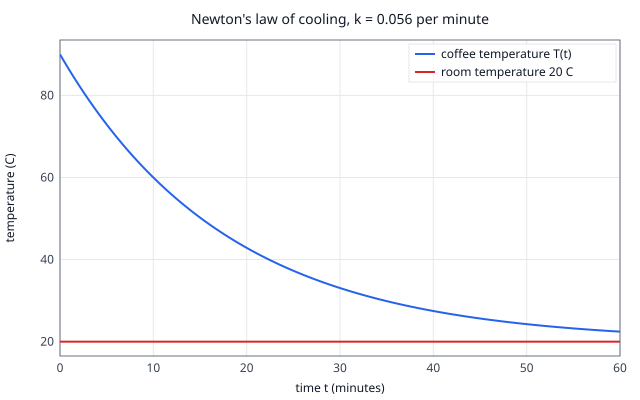

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [7]:
k = log(7/4)/10;
eval(k)
p = plot(T, 20, t, 0, 60);
p = legend(p, "coffee temperature T(t)", "room temperature 20 C");
labels(title(p, "Newton's law of cooling, k = 0.056 per minute"), "time t (minutes)", "temperature (C)")
clear

## 3. The spring: second-order equations

A mass on a spring feels a force pulling it back, proportional to the stretch $y$. Newton's law $F = ma$ gives
$m y'' = -c\,y$, or with $\omega^2 = c/m$

$$y'' + \omega^2 y = 0.$$

A second-order equation needs two initial conditions: where the mass starts, $y(0)$, and how fast, $y'(0)$.

In [8]:
dsolve(d(y, t, 2) + w^2*y == 0, y, t)
dsolve(d(y, t, 2) + 4*y == 0, y, t, 0, [1, 0])

C1*cos(t*w)+C2*sin(t*w)

> `dsolve`: Exact solution of a differential equation written with y, d(y, x), d(y, x, 2), ...: linear with constant coefficients of any order (forcing by polynomials, exponentials, sines and cosines), first-order linear y' + p(x) y = q(x), separable y' = f(x) g(y) (logistic, y' = x/y, ...), and Cauchy–Euler x^2 y'' + b x y' + c y = 0.

cos(2*t)

> `dsolve`: Exact solution of a differential equation written with y, d(y, x), d(y, x, 2), ...: linear with constant coefficients of any order (forcing by polynomials, exponentials, sines and cosines), first-order linear y' + p(x) y = q(x), separable y' = f(x) g(y) (logistic, y' = x/y, ...), and Cauchy–Euler x^2 y'' + b x y' + c y = 0.

Without friction the spring oscillates forever, with angular frequency $\omega$ (here 2, so the period is
$2\pi/2 = \pi$).

### Damping

Friction adds a force against the velocity: $y'' + c\,y' + 4y = 0$. How the spring moves depends on the friction
constant $c$. The **characteristic equation** $r^2 + c r + 4 = 0$ (put $y = e^{rt}$ into the equation) decides:

* $c^2 < 16$: complex roots, the spring still oscillates while the swings die out (**underdamped**);
* $c^2 = 16$: one double root, the fastest return without overshooting (**critically damped**);
* $c^2 > 16$: two negative real roots, a slow creep back (**overdamped**).

In [9]:
under = dsolve(d(y, t, 2) + 2*d(y, t) + 4*y == 0, y, t, 0, [1, 0])
critical = dsolve(d(y, t, 2) + 4*d(y, t) + 4*y == 0, y, t, 0, [1, 0])
over = dsolve(d(y, t, 2) + 5*d(y, t) + 4*y == 0, y, t, 0, [1, 0])

exp(-t)*sin(sqrt(3)*t)/sqrt(3)+exp(-t)*cos(sqrt(3)*t)

> `dsolve`: Exact solution of a differential equation written with y, d(y, x), d(y, x, 2), ...: linear with constant coefficients of any order (forcing by polynomials, exponentials, sines and cosines), first-order linear y' + p(x) y = q(x), separable y' = f(x) g(y) (logistic, y' = x/y, ...), and Cauchy–Euler x^2 y'' + b x y' + c y = 0.

exp(-2*t)*(2*t+1)

> `dsolve`: Exact solution of a differential equation written with y, d(y, x), d(y, x, 2), ...: linear with constant coefficients of any order (forcing by polynomials, exponentials, sines and cosines), first-order linear y' + p(x) y = q(x), separable y' = f(x) g(y) (logistic, y' = x/y, ...), and Cauchy–Euler x^2 y'' + b x y' + c y = 0.

4*exp(-t)/3-exp(-4*t)/3

> `dsolve`: Exact solution of a differential equation written with y, d(y, x), d(y, x, 2), ...: linear with constant coefficients of any order (forcing by polynomials, exponentials, sines and cosines), first-order linear y' + p(x) y = q(x), separable y' = f(x) g(y) (logistic, y' = x/y, ...), and Cauchy–Euler x^2 y'' + b x y' + c y = 0.

All three start at $y = 1$ at rest. The horizontal axis is time, the vertical axis the position of the mass (0 is
the resting position):

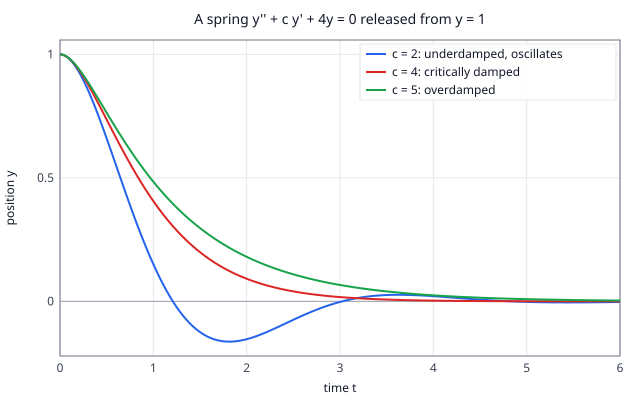

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [10]:
p = plot(under, critical, over, t, 0, 6);
p = legend(p, "c = 2: underdamped, oscillates", "c = 4: critically damped", "c = 5: overdamped");
labels(title(p, "A spring y'' + c y' + 4y = 0 released from y = 1"), "time t", "position y")

Car shock absorbers are tuned close to critical damping: as fast as possible back to rest without bouncing.

### Resonance

Push the spring periodically with a force $\cos(\Omega t)$: $y'' + 4y = \cos(\Omega t)$. If the push has a
different frequency than the spring, the motion stays bounded. If it has exactly the spring's own frequency
$\Omega = 2$, every push adds to the swing and the amplitude grows without limit: **resonance**.

cos(t)/3-cos(2*t)/3

> `dsolve`: Exact solution of a differential equation written with y, d(y, x), d(y, x, 2), ...: linear with constant coefficients of any order (forcing by polynomials, exponentials, sines and cosines), first-order linear y' + p(x) y = q(x), separable y' = f(x) g(y) (logistic, y' = x/y, ...), and Cauchy–Euler x^2 y'' + b x y' + c y = 0.

t*sin(2*t)/4

> `dsolve`: Exact solution of a differential equation written with y, d(y, x), d(y, x, 2), ...: linear with constant coefficients of any order (forcing by polynomials, exponentials, sines and cosines), first-order linear y' + p(x) y = q(x), separable y' = f(x) g(y) (logistic, y' = x/y, ...), and Cauchy–Euler x^2 y'' + b x y' + c y = 0.

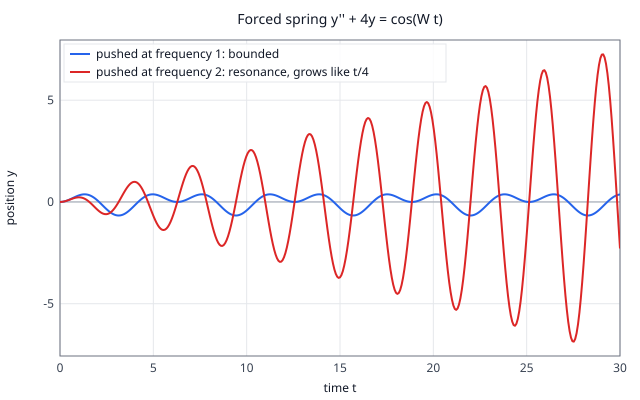

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [11]:
off = dsolve(d(y, t, 2) + 4*y == cos(t), y, t, 0, [0, 0])
res = dsolve(d(y, t, 2) + 4*y == cos(2*t), y, t, 0, [0, 0])
p = plot(off, res, t, 0, 30);
p = legend(p, "pushed at frequency 1: bounded", "pushed at frequency 2: resonance, grows like t/4");
labels(title(p, "Forced spring y'' + 4y = cos(W t)"), "time t", "position y")

Resonance is why soldiers break step on bridges, and how a radio picks one station out of many.

## 4. When there is no formula: numeric solutions

Most differential equations, especially **nonlinear** ones, have no solution formula. Then we solve them
numerically: start at the initial value and take many small steps, each following the slope the equation
prescribes (Galileo uses the Runge–Kutta method, 20000 steps by default).

### Logistic growth

A population $P$ grows like $P' = rP$ while it is small, but food runs out near the **carrying capacity** $K$:

$$P' = r P \left(1 - \frac{P}{K}\right).$$

This one happens to have a formula (it is *separable*: see
[differential equations 1](../differential-equations/01-first-order-equations.ipynb)), but most nonlinear equations
do not, so here we practise the numeric way. There are two commands:

* `odesolve(rhs, unknowns, t, start, t0, t1)` returns the value of the unknowns at the end time $t_1$;
* `odeplot(rhs, unknowns, t, start, t0, t1, [X Y])` draws the solution.

Their arguments, one by one, for $P' = rP(1 - P/K)$ starting with $P = 0.5$ at time 0:

| # | argument | here | meaning |
|---|---|---|---|
| 1 | `rhs` | `[r*P*(1 - P/K)]` | the right-hand side: the formula for $P'$, in brackets (one entry per equation) |
| 2 | `unknowns` | `[P]` | the names of the unknown functions, in the same order |
| 3 | `t` | `t` | the name of the independent variable (time) |
| 4 | `start` | `[0.5]` | the values of the unknowns at the start time |
| 5 | `t0` | `0` | the start time |
| 6 | `t1` | `12` | the end time |
| 7 | `[X Y]` | `[t P]` | (odeplot only) what to draw: $X$ across, $Y$ up. `[t P]` draws $P$ against time |

Parameters such as $r$ and $K$ need values first.

In [12]:
r = 1; K = 10;
odesolve([r*P*(1 - P/K)], [P], t, [0.5], 0, 12)

9.998832735919308

> `odesolve`: Solves the system of first-order equations dy/dt = rhs numerically (Runge-Kutta) from t = t0 to t = t1 and returns the unknowns at t1: a number for one unknown, a row otherwise.

At $t = 12$ the population is very close to $K = 10$. The plot of the whole history:

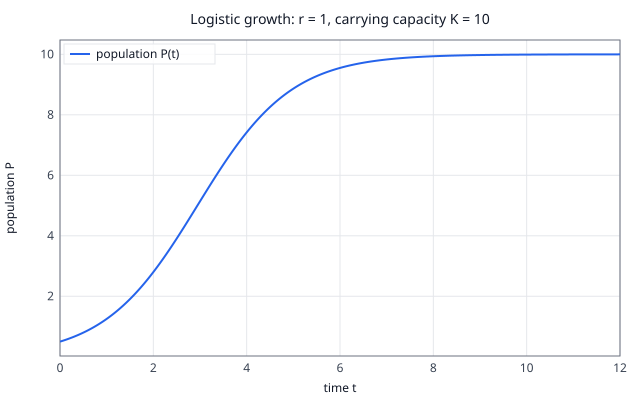

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [13]:
p = odeplot([r*P*(1 - P/K)], [P], t, [0.5], 0, 12, [t P]);
labels(title(legend(p, "population P(t)"), "Logistic growth: r = 1, carrying capacity K = 10"), "time t", "population P")

The curve has the typical S-shape: exponential growth at first, fastest growth at $P = K/2 = 5$, then levelling off
at $K$. Several starting values at once: give one start value per row of `start`. Starting above $K$ the
population shrinks back to $K$:

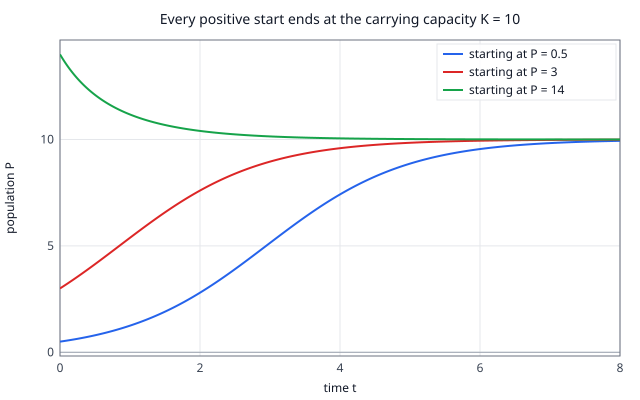

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [14]:
p = odeplot([r*P*(1 - P/K)], [P], t, [0.5; 3; 14], 0, 8, [t P]);
p = legend(p, "starting at P = 0.5", "starting at P = 3", "starting at P = 14");
labels(title(p, "Every positive start ends at the carrying capacity K = 10"), "time t", "population P")
clear

### The pendulum

A pendulum of length $L$ swings at angle $\theta$ from the vertical. Gravity gives

$$\theta'' = -\frac{g}{L}\sin\theta.$$

The $\sin\theta$ makes it nonlinear. `odeplot` only takes **first-order** equations, so we use a standard trick: give
the angular velocity its own name, $\omega = \theta'$. Then the one second-order equation becomes two first-order ones:

$$\theta' = \omega, \qquad \omega' = -\frac{g}{L}\sin\theta.$$

The arguments for odeplot are now:

1. `[w, -g/L*sin(th)]`: the right-hand sides, $\theta' = \omega$ and $\omega' = -\frac gL \sin\theta$ (we write `th` and `w` for $\theta$ and $\omega$);
2. `[th w]`: the unknowns, in the same order as the right-hand sides;
3. `t`: time;
4. `[2.5 0]`: start at angle 2.5 radians (about 143°, almost upside down) and at rest;
5. `0`: start time; 6. `10`: end time, in seconds;
7. `[t th]`: draw the angle against time.

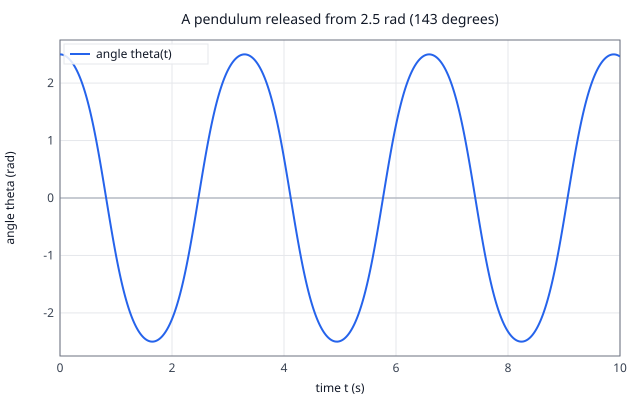

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [15]:
g = 9.81; L = 1;
p = odeplot([w, -g/L*sin(th)], [th w], t, [2.5 0], 0, 10, [t th]);
labels(title(legend(p, "angle theta(t)"), "A pendulum released from 2.5 rad (143 degrees)"), "time t (s)", "angle theta (rad)")

For small angles $\sin\theta \approx \theta$, and the equation becomes the spring equation $\theta'' + \frac gL\theta = 0$,
which `dsolve` solves exactly. How good is that approximation? Compare both for a small swing (0.2 rad, about 11°)
and a large one (2.5 rad). `show` overlays the plots:

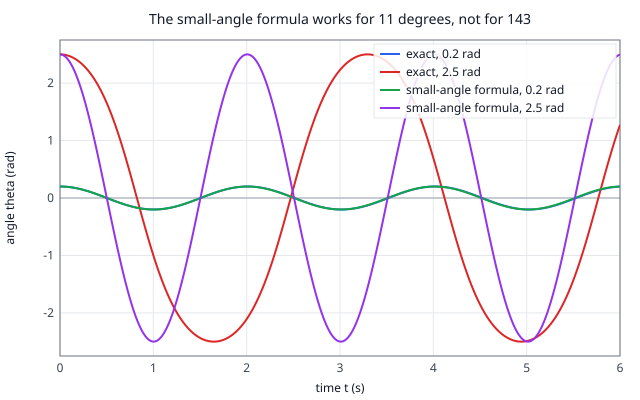

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [16]:
small = dsolve(d(th, t, 2) + g/L*th == 0, th, t, 0, [0.2, 0]);
big = dsolve(d(th, t, 2) + g/L*th == 0, th, t, 0, [2.5, 0]);
p1 = odeplot([w, -g/L*sin(th)], [th w], t, [0.2 0; 2.5 0], 0, 6, [t th]);
p = show(p1, plot(small, big, t, 0, 6));
p = legend(p, "exact, 0.2 rad", "exact, 2.5 rad", "small-angle formula, 0.2 rad", "small-angle formula, 2.5 rad");
labels(title(p, "The small-angle formula works for 11 degrees, not for 143"), "time t (s)", "angle theta (rad)")

For 0.2 rad the formula and the true motion coincide. For 2.5 rad the true pendulum is much slower: big swings take
longer, so pendulum clocks keep time only when their swing is small.

### Phase portraits

Instead of plotting the angle against time we can plot the angular velocity $\omega$ against the angle $\theta$:
`[th w]` as the last argument. Each solution becomes a curve in this **phase plane**, and time is the position along
the curve. Here are four swings, starting at rest at 0.5, 1.5, 2.5 and 3.0 rad (one row of `starts` per swing):

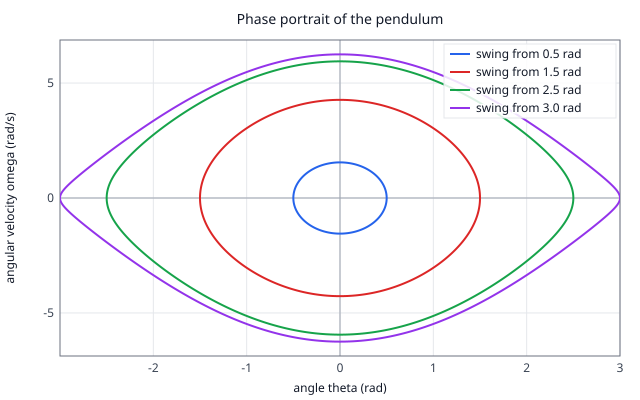

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [17]:
starts = [0.5 0; 1.5 0; 2.5 0; 3.0 0];
p = odeplot([w, -g/L*sin(th)], [th w], t, starts, 0, 6, [th w]);
p = legend(p, "swing from 0.5 rad", "swing from 1.5 rad", "swing from 2.5 rad", "swing from 3.0 rad");
labels(title(p, "Phase portrait of the pendulum"), "angle theta (rad)", "angular velocity omega (rad/s)")

How to read it: the horizontal axis is the angle, the vertical axis the angular velocity. A swing is a closed loop,
run through clockwise: the pendulum moves right (positive $\omega$, upper half), stops at its largest angle
($\omega = 0$), and comes back (lower half). Small swings are almost ellipses (the spring); large swings get pointed
near $\theta = \pm\pi$, the upside-down position.

Start at the bottom with enough speed and the pendulum goes over the top and keeps spinning. Its phase curve never
closes: the angle keeps growing while the speed wobbles (fastest at the bottom, slowest at the top).

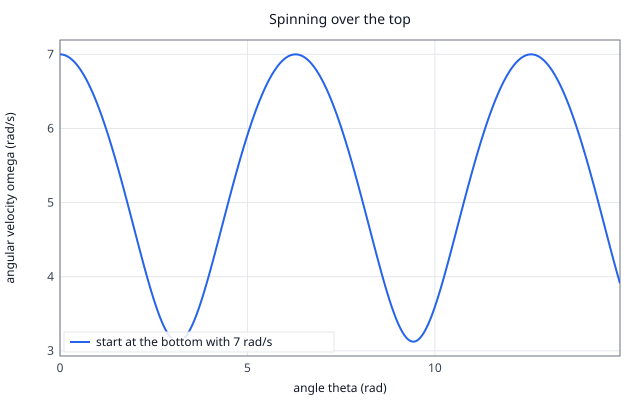

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [18]:
p = odeplot([w, -g/L*sin(th)], [th w], t, [0 7], 0, 3, [th w]);
labels(title(legend(p, "start at the bottom with 7 rad/s"), "Spinning over the top"), "angle theta (rad)", "angular velocity omega (rad/s)")

## Summary

* A differential equation relates a function to its derivatives; check a solution by substituting it.
* `dsolve(eq, y, t)` solves linear equations exactly; `dsolve(eq, y, t, t0, [y(t0), d(y, t0), ...])` adds initial conditions.
* Exponential growth and decay, cooling, the spring: damping and resonance follow from the characteristic equation.
* Nonlinear equations: write them as first-order systems and use `odesolve` (end values) and `odeplot` (pictures),
  with arguments: right-hand sides, unknowns, time variable, start values, start time, end time, what to draw.
* A phase portrait plots one unknown against another; closed loops are oscillations.

**Try it:** change the damping constant in the spring to 3.9 and 4.1. Add friction to the pendulum,
$\omega' = -\frac gL\sin\theta - 0.3\,\omega$, and draw its phase portrait: what happens to the loops?

Next: [Geometry and conic sections](09-geometry-and-conics.ipynb). For much more on this topic, the
[differential equations](../differential-equations/README.md) path is a full first course.

## Sources

1. W. E. Boyce and R. C. DiPrima, *Elementary Differential Equations and Boundary Value Problems*, 10th ed., Wiley (2012). Chapters 2 and 3 (first-order equations, second-order linear equations, damping and resonance).
2. S. H. Strogatz, *Nonlinear Dynamics and Chaos*, 2nd ed., Westview Press (2015). Sections 2.3 (logistic growth) and 6.7 (the pendulum and its phase portrait).
3. W. F. Libby, "Radiocarbon dating", Nobel lecture (1960).